# T2. Training a learner against an exact benchmark

The point of barrier policy gradients is that the learner stays unchanged: the remaining budget enters the
state, the reward is replaced by the clipped barrier reward, and PPO trains as usual. This notebook trains
PPO (Stable-Baselines3) on the wear-allowance problem of notebook T1 and supplies the evidence a practitioner
needs afterwards:

* training traces that show whether the run has converged,
* the deployed candidates (stochastic and mean-action) evaluated separately,
* the optimization error, measured against the exact frontier that this problem happens to have,
* training at several prices, checked against the price–risk law and the price-sequence condition,
* an adaptive multiplier toward a prescribed level, with a diagnosis of its trace,
* the margin bought by the interior barrier under a misjudged allowance,
* the report.

Requires the RL extras: `pip install -e ".[rl]"`. Each run here trains for two million steps (about a minute and
a half on one CPU core) with the paper's PPO settings; the paper's campaign used eight million steps and eight
seeds per configuration. The whole notebook takes about eleven minutes on one CPU core.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

import bpg
from bpg import Requirement, Stage, evaluate, interpret, sb3_policy
from bpg.callbacks import BudgetMonitor, DualAscent, dual_step_suggestion
from bpg.convergence import seed_dispersion
from bpg.examples.wear import WearModel, make_wear_env, EXACT_FRONTIER, EXACT_BARRIER
from bpg.frontier import Run, check_runs, interpolate_frontier, price_sequence_check
from bpg.spec import discounted_total, price_from_multiplier

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
model = WearModel(); spec = model.spec(ubar=1.0)
req = Requirement(T=19, alpha=0.05, zeta=0.05, family=12)       # every learned candidate inspected below shares the error

## A training helper

The environment is the wrapper of notebook T1. PPO uses algorithmic discount one: the wrapper's geometric stopping
implements $\beta$ exactly. Reward normalization keeps the scale of the failure tail $m/(1-\beta)$ manageable,
which matters when the price is large. The settings are the paper's: 32 environments, rollouts of 256 steps,
minibatches of 1024, ten epochs, a learning rate decaying linearly to zero, no entropy bonus.

In [2]:
def train(stage, seed=0, steps=2_000_000, callbacks=(), n_envs=32):
    venv = DummyVecEnv([lambda: make_wear_env(stage, model) for _ in range(n_envs)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=1e9, gamma=1.0)
    ppo = PPO("MlpPolicy", venv, seed=seed, n_steps=256, batch_size=1024, n_epochs=10, learning_rate=lambda p: 3e-4 * p, gamma=1.0,
              gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, policy_kwargs=dict(net_arch=[64, 64], log_std_init=-1.0),
              device="cpu", verbose=0)
    ppo.learn(total_timesteps=steps, callback=list(callbacks))
    return ppo


def exact_value(m):
    """V_m of the exact failure-only optimum at price m (grid values from the paper's dynamic program)."""
    q, U = EXACT_FRONTIER[m]
    return U - m * q / (1 - spec.beta)

## A fixed price, with its training trace

`BudgetMonitor` records per rollout the failure rate, the stopped utility, the clipped value and the action
dispersion, and tests the last rollouts for a remaining trend. A trend means the candidate is the policy at the
end of the run, not one at which training has converged.

V_m: no trend detectable at two standard errors over the last 40 points (mean 3.68, noise sd 0.168)
U: no trend detectable at two standard errors over the last 40 points (mean 4.298, noise sd 0.11)
failure_rate: no trend detectable at two standard errors over the last 40 points (mean 0.0309, noise sd 0.0086)
near: no trend detectable at two standard errors over the last 40 points (mean 0.04913, noise sd 0.0125)
log_std: still falling over the last 40 points (drift 1.18% of its level per window)
last rollout: failure rate 0.0267, U 4.557, V_m 4.023
the action dispersion is still changing: the candidate is not yet fixed, and a policy with a different dispersion is a different candidate
trace diagnostics are evidence about this run, not a convergence theorem [paper, 'Scope of the guarantees']


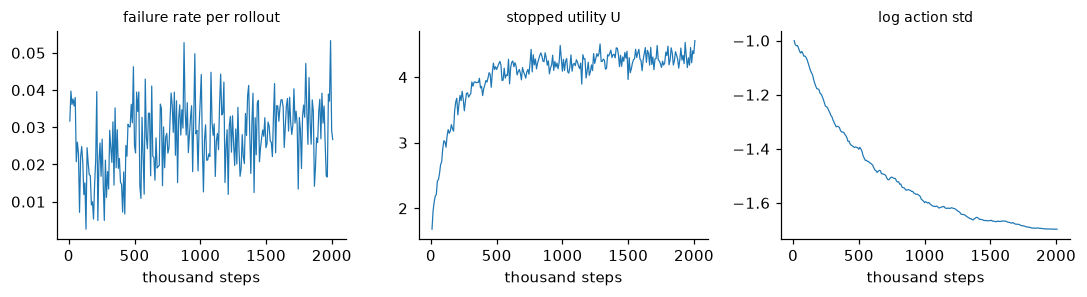

In [3]:
stage = Stage(m=1.0)
mon = BudgetMonitor(spec.beta, stage.m)
ppo = train(stage, seed=0, callbacks=[mon])
print(mon.explain(window=40))

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
steps = mon.series("steps") / 1e3
for ax, key, lab in zip(axes, ("failure_rate", "U", "log_std"), ("failure rate per rollout", "stopped utility U", "log action std")):
    ax.plot(steps, mon.series(key), lw=0.8); ax.set_xlabel("thousand steps"); ax.set_title(lab, fontsize=9)
plt.tight_layout(); plt.show()

## Two candidates from one network

The stochastic policy and its **mean-action** policy (the same network without its dispersion) are different
candidates; each needs its own evaluation and validation. Because this problem has an exact solution, we can
also measure the **optimization error**: the shortfall of the learned clipped value from the exact optimum at the
same price. The paper's fixed-price results charge exactly this quantity, written $\delta$.

In [4]:
env = lambda: make_wear_env(stage, model)
ev_s = evaluate(env, sb3_policy(ppo, deterministic=False), 10_000, spec=spec, stage=stage, seed=1, T=19)
ev_d = evaluate(env, sb3_policy(ppo, deterministic=True), 10_000, spec=spec, stage=stage, seed=2, T=19)
for name, e in (("stochastic", ev_s), ("mean-action", ev_d)):
    delta = exact_value(1.0) - e.V_m
    print(f"{name:11s} q_beta = {e.q_beta:.4f}  U = {e.U:.3f}  V_m = {e.V_m:.3f}  delta = {delta:+.3f}  "
          f"near-exhaustion = {e.near[0.05]:.3f}")
print(f"exact optimum at m = 1: q_beta = {EXACT_FRONTIER[1.0][0]:.4f}, U = {EXACT_FRONTIER[1.0][1]:.3f}, V_m = {exact_value(1.0):.3f}")

stochastic  q_beta = 0.0273  U = 4.289  V_m = 3.743  delta = +0.580  near-exhaustion = 0.047
mean-action q_beta = 0.0173  U = 4.094  V_m = 3.748  delta = +0.575  near-exhaustion = 0.025
exact optimum at m = 1: q_beta = 0.0145, U = 4.613, V_m = 4.323


## Training at several prices

The price selects a point on the frontier; it does not prescribe a risk level. Training at three prices, with a
second seed at $m=1$, shows the price–risk trade-off on the learned policies. `check_runs` compares them with the
price–risk law and with monotonicity in the price, and flags runs that are dominated (a sign of optimization
error, not of the formulation).

In [5]:
prices = (0.3, 1.0, 3.0)
by_price = {(1.0, 0): ev_s}                                   # the run above
for mm, sd in ((0.3, 0), (3.0, 0), (1.0, 1)):
    st = Stage(m=mm)
    pol = train(st, seed=sd)
    by_price[(mm, sd)] = evaluate(lambda: make_wear_env(st, model), sb3_policy(pol), 10_000, spec=spec, stage=st, seed=100 + sd, T=19)
for (mm, sd), e in sorted(by_price.items()):
    print(f"m = {mm:<4g} seed {sd}: q_beta = {e.q_beta:.4f} (exact {EXACT_FRONTIER[mm][0]:.4f}), U = {e.U:.3f} "
          f"(exact {EXACT_FRONTIER[mm][1]:.3f}), delta = {exact_value(mm) - e.V_m:+.3f}")

m = 0.3  seed 0: q_beta = 0.0541 (exact 0.0406), U = 4.646 (exact 4.888), delta = +0.323
m = 1    seed 0: q_beta = 0.0273 (exact 0.0145), U = 4.289 (exact 4.613), delta = +0.580
m = 1    seed 1: q_beta = 0.0302 (exact 0.0145), U = 4.322 (exact 4.613), delta = +0.605
m = 3    seed 0: q_beta = 0.0132 (exact 0.0045), U = 3.900 (exact 4.275), delta = +0.896


m=0.3      q=0.0541  U-I=4.646  law bound=1
m=1        q=0.0273  U-I=4.289  law bound=0.3165
m=1        q=0.0302  U-I=4.322  law bound=0.3165
m=3        q=0.0132  U-I=3.9  law bound=0.1055
monotonicity in the price: consistent within the stated optimization errors [paper, 'Fixed price of failure risk' (monotonicity in the price)]
dominated in (q_beta, U - I_m): m=1 seed 0 (q=0.0273, U-I=4.289) is dominated by m=1 seed 1 (q=0.0302, U-I=4.322)
a fixed-price optimum lies on the frontier of U - I_m against q_beta; a point strictly below another with no greater risk indicates optimization error (or a non-optimal policy), not a property of the formulation


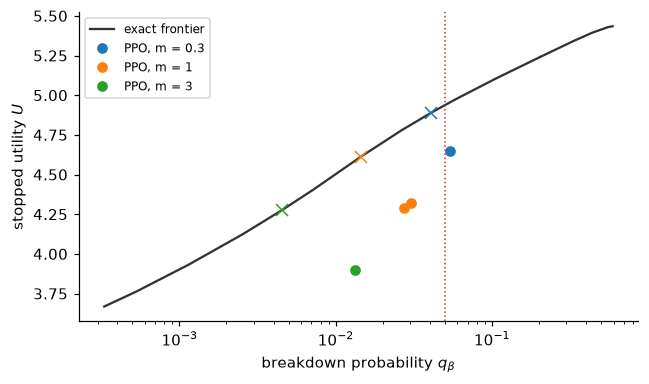

In [6]:
runs = [Run(m=mm, q_beta=e.q_beta, U=e.U, label=f"seed {sd}") for (mm, sd), e in by_price.items()]
deltas = {mm: max(0.0, max(exact_value(mm) - e.V_m for (k, sd), e in by_price.items() if k == mm)) for mm in prices}
chk = check_runs(runs, beta=spec.beta, sup_U=EXACT_FRONTIER[0.0][1], delta=max(deltas.values()), tol=0.005)
print(chk.explain())

qf = np.array([v[0] for v in EXACT_FRONTIER.values()]); Uf = np.array([v[1] for v in EXACT_FRONTIER.values()]); o = np.argsort(qf)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(qf[o], Uf[o], color="0.2", label="exact frontier")
for i, mm in enumerate(prices):
    pts = [e for (k, sd), e in by_price.items() if k == mm]
    ax.plot([e.q_beta for e in pts], [e.U for e in pts], "o", color=f"C{i}", label=f"PPO, m = {mm:g}")
    ax.plot(*EXACT_FRONTIER[mm], "x", color=f"C{i}", ms=8)
ax.axvline(0.05, color="C3", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("breakdown probability $q_\\beta$"); ax.set_ylabel("stopped utility $U$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Crosses mark the exact optimum at each price. The learned policies follow the price: a higher price buys a lower
breakdown probability at a utility cost. Each lies short of the exact point at its price by its optimization
error $\delta$, which this problem lets us measure.

**Can raising the price reach a tolerance?** By the paper's *Price sequences reaching a tolerance*, a sequence of prices reaches a tolerance
when some policy has risk to spare and the charged errors grow slower than the price. `price_sequence_check` reads
that condition from the measured shortfalls. In the paper's emissions study PPO failed it: its shortfall grew in
proportion to the price.

In [7]:
print(price_sequence_check(list(deltas), list(deltas.values())).explain())

m=0.3      charged=0.3231  charged/m=1.077
m=1        charged=0.6049  charged/m=0.6049
m=3        charged=0.896  charged/m=0.2987
the charged errors shrink relative to the price (charged/m 0.605 -> 0.299; log-log slope 0.44): consistent with a sequence of prices reaching a tolerance that some comparison policy meets with risk to spare [paper, 'Price sequences reaching a tolerance']


With three prices and one or two seeds this is a rough reading of one learner at one training budget. The check is
most useful on short pilot runs at a few prices before committing to a large price: a shortfall that grows in proportion to the
price says that raising the price will not reach a smaller tolerance with this learner.

## A prescribed level: the adaptive multiplier

A multiplier method charges a flat penalty $\nu$ at failure and updates it after each rollout,
$\nu\leftarrow\max\{0,\nu+c(\hat q-\alpha)\}$. If it converges to $\nu$, it returns the fixed-price optimum at
$m=(1-\beta)\nu$ (the paper's section *The fixed price of failure risk*). The step $c$ is sized from the level the
multiplier has to reach. The learned policies above attain more risk than the exact optima at the same price, so
that level comes from the learned runs, not from the exact frontier: we interpolate, on a log scale, the price at
which they attain the prescribed level. Sized from the exact frontier, which attains it at about a third of that
price, the multiplier is still rising when training ends.

The step is half the expected level per rollout in which every episode fails. Early in training, when many episodes
fail, the multiplier rises within a few rollouts. Near the tolerance, where the failure rate is off by about a
percentage point, one rollout moves it by about half a percent of its level, slowly relative to the policy's updates.

The prescribed level is set **below** the tolerance: a multiplier that converges at the tolerance itself does not pass
validation at that tolerance.

the learned runs attain 0.02 near m = 1.67: expected multiplier nu = 33.4


stable | multiplier 30.05 (price-equivalent m = (1-beta) nu = 1.502) shows no drift over the last 40 rollouts (+0.0208 per rollout, standard error 0.021), and the failure rate 0.0212 is near the tolerance 0.02. A multiplier that has converged returns the fixed-price optimum at that price; a level reached at the tolerance itself does not pass a validation test at that tolerance


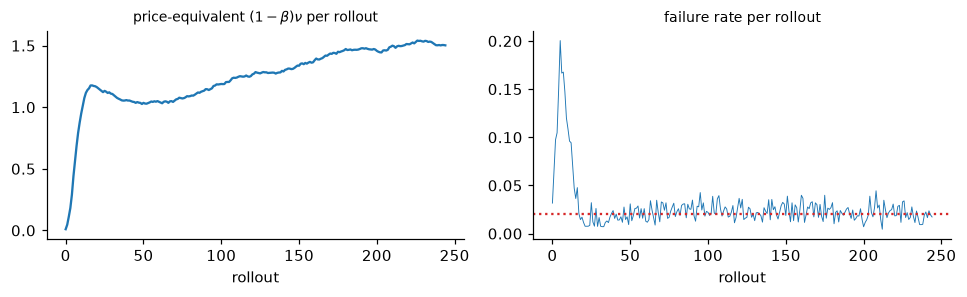

adaptive candidate: q_beta = 0.0173, U = 4.095, final nu = 30.05 (price-equivalent m = 1.502)


In [8]:
alpha_level = 0.02
m_runs = sorted(prices)
q_runs = [np.mean([e.q_beta for (k, sd), e in by_price.items() if k == mm]) for mm in m_runs]   # risk falls with the price
m_expected = float(np.exp(np.interp(np.log(alpha_level), np.log(q_runs[::-1]), np.log(m_runs[::-1]))))
nu_expected = discounted_total(m_expected, spec.beta)
print(f"the learned runs attain {alpha_level:g} near m = {m_expected:.2f}: expected multiplier nu = {nu_expected:.1f}")
dual = DualAscent(alpha=alpha_level, step=dual_step_suggestion(nu_expected, rollouts_to_reach=2))
adaptive_stage = Stage(m=0.0, penalty="multiplier")
mon_a = BudgetMonitor(spec.beta, 0.0, penalty="multiplier", dual=dual)
ppo_a = train(adaptive_stage, seed=0, callbacks=[dual, mon_a])
diag = dual.diagnose(spec.beta, window=40)
print(diag.status, "|", diag.explanation)

nu = np.array([t["multiplier"] for t in dual.trace]); fr = np.array([t["failure_rate"] for t in dual.trace])
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].plot(nu * (1 - spec.beta)); axes[0].set_title("price-equivalent $(1-\\beta)\\nu$ per rollout", fontsize=9)
axes[1].plot(fr, lw=0.6); axes[1].axhline(alpha_level, color="C3", ls=":"); axes[1].set_title("failure rate per rollout", fontsize=9)
for ax in axes: ax.set_xlabel("rollout")
plt.tight_layout(); plt.show()

final_stage = adaptive_stage.with_(multiplier=dual.multiplier)
ev_a = evaluate(lambda: make_wear_env(final_stage, model), sb3_policy(ppo_a), 10_000, spec=spec, stage=final_stage, seed=3, T=19)
print(f"adaptive candidate: q_beta = {ev_a.q_beta:.4f}, U = {ev_a.U:.3f}, final nu = {dual.multiplier:.2f} "
      f"(price-equivalent m = {price_from_multiplier(dual.multiplier, spec.beta):.3f})")

Read the diagnosis printed above. It applies the paper's two criteria for convergence: the multiplier stops moving,
and the attained risk lies within the confidence bound of the tolerance. *Stable* means both hold, and the
candidate is the fixed-price optimum at the price-equivalent $m=(1-\beta)\nu$, up to its optimization error.
The multiplier is the running sum of its updates, so the diagnosis tests whether it still moves on the updates
themselves: their mean over the last rollouts is its drift. *Trending* means the multiplier was still moving when
training stopped: the candidate is not a fixed-price optimum at any identified price, and longer training or a step
sized from the level the multiplier has to reach is needed. A multiplier that keeps rising while the failure rate
stays above the tolerance is the sign of a tolerance below the risk floor of the class, where no multiplier
converges. *Increasing* means the multiplier rose while every episode failed, so the flat penalty carried no
gradient (the fuel-tank study). *Off-target* means no drift but a failure rate away from the tolerance: the
rollouts are too few or too small to resolve it.

## Buying a margin: the interior barrier under a misjudged allowance

A failure-only price leaves no reserve: its optimal policies run close to exhaustion whenever that pays. If the
true allowance is ten percent smaller than the one the policy observes, breakdowns rise sharply. The interior
barrier ($\theta>0$) keeps a graded margin at a utility cost bounded by its interior loss. The wrapper option
`true_budget_scale=0.9` judges failure against the reduced allowance while the policy sees the nominal reserve.

In [9]:
barrier_stage = Stage(m=1.0, theta=0.1)
ppo_b = train(barrier_stage, seed=0)
rows = []
for name, pol, st in (("failure-only price", ppo, stage), ("interior barrier", ppo_b, barrier_stage)):
    nominal = evaluate(lambda: make_wear_env(st, model), sb3_policy(pol), 6000, spec=spec, stage=st, seed=5)
    reduced = evaluate(lambda: make_wear_env(st, model, true_budget_scale=0.9), sb3_policy(pol), 6000, spec=spec, stage=st, seed=5)
    rows.append((name, nominal.q_beta, nominal.U, nominal.I_m, nominal.near[0.05], reduced.q_beta))
print(f"{'':20s} {'q_beta':>8s} {'U':>6s} {'I_m':>6s} {'near':>6s} {'q at 0.9b':>10s}")
for r in rows:
    print(f"{r[0]:20s} {r[1]:8.4f} {r[2]:6.3f} {r[3]:6.3f} {r[4]:6.3f} {r[5]:10.4f}")

                       q_beta      U    I_m   near  q at 0.9b
failure-only price     0.0252  4.317  0.000  0.045     0.0908
interior barrier       0.0058  3.645  2.515  0.009     0.0170


The barrier gives up utility at the nominal allowance and keeps breakdowns low when the allowance is misjudged.
If the size of the possible error is known, planning with a correspondingly tightened allowance is the more
economical margin; the barrier is the graded margin for an error of unknown size.

## Validate and report

The fixed-price stochastic candidate is the one we would deploy. Its optimization error is known here from the
exact optimum, so the report can state the fixed-price reading with that $\delta$. Every learned candidate
inspected in this notebook shares the validation error (`family=12`). The requirement $p_{19}\le0.05$ is tested
here through $q_\beta\le0.05\,\beta^{19}$, which is conservative under geometric stopping; notebook T4 tests
$p_T$ directly.

In [10]:
delta_s = max(0.0, exact_value(1.0) - ev_s.V_m)
gap = (interpolate_frontier([Run(m=k, q_beta=q, U=U) for k, (q, U) in EXACT_FRONTIER.items()], ev_s.q_beta) - ev_s.U) / ev_s.U
seeds_q = seed_dispersion([by_price[(1.0, 0)].q_beta, by_price[(1.0, 1)].q_beta])
rep = interpret(spec, req, stage, ev_s, sup_U=EXACT_FRONTIER[0.0][1], delta=delta_s, trends=mon.diagnostics(window=40),
                seeds={"q_beta at m = 1": seeds_q}, exact_frontier_gap=gap)
print(rep.text())

Candidate under price m = 1; requirement p_19 <= 0.05 at error 0.05/12.

Measured on fresh episodes:
  n=10000: p_T censored by the geometric clock (273 failures counted for q_beta), q_beta=0.0273, U=4.289±0.023, I_m=0, V_m=3.743±0.041, mean length 19.4
  near-exhaustion (min reserve <=): 0.02b: 0.0336, 0.05b: 0.0469, 0.1b: 0.0892, 0.2b: 0.344

Verdict: NOT certified at the specified horizon (failure to certify does not prove violation).

In what sense the candidate is a solution:
  - Fixed-price reading (paper, 'Fixed price of failure risk' (optimality at the attained risk)): among the policies of its class with no greater geometric risk, the final stochastic policy maximizes U - I_m up to the optimization error delta = 0.58; it is optimal at the risk it attains, q_beta = 0.0273. Where on the frontier it lies is not controlled by m. Its risk is above the geometric level alpha beta^T = 0.01887, so it has no unused risk at that level; validation decides the finite-horizon requirement.



The route through $q_\beta$ is conservative under geometric stopping: $q_\beta$ counts every failure before
maintenance access, including failures long after action 19. The requirement concerns $p_{19}$, so we validate it
directly on fresh episodes over a fixed horizon of 20 actions, without the clock. The same network is the same
candidate here; only the evaluation changes.

In [11]:
from bpg import BudgetWrapper
from bpg.examples.wear import WearCore, wear_cost
fixed_spec = spec.with_(horizon=req.T + 1)
ev_fixed = evaluate(lambda: BudgetWrapper(WearCore(model), wear_cost, fixed_spec, stage, geometric_stop=False), sb3_policy(ppo),
                    10_000, spec=fixed_spec, stage=stage, seed=9, T=req.T)
rep_fixed = interpret(fixed_spec, req, stage, ev_fixed, delta=None)
print(f"p_19 = {ev_fixed.p_T:.4f}; certified: {rep_fixed.certified}")
print("\n".join(rep_fixed.text().split("\n")[:12]))

p_19 = 0.0337; certified: True
Candidate under price m = 1; requirement p_19 <= 0.05 at error 0.05/12.

Measured on fresh episodes:
  n=10000: p_T(T=19)=0.0337 (337 failures counted for p_T), q_beta=0.02368, U=4.155±0.013, I_m=0, V_m=3.846±0.024, mean length 19.6
  near-exhaustion (min reserve <=): 0.02b: 0.0404, 0.05b: 0.0536, 0.1b: 0.0945, 0.2b: 0.391

Verdict: CERTIFIED by direct validation at the specified horizon.

In what sense the candidate is a solution:
  - Optimization error is unknown: no optimality or convergence claim is made for this candidate. The finite-price objective trades stopped utility and interior loss against failure risk; direct validation assesses the executed candidate independently of optimization.

Evidence and bounds:


## Summary

* PPO is trained unchanged; the wrapper carries the budget and the clipped reward.
* The learned fixed-price policies follow the price and fall short of the exact optimum by an optimization error
  that this problem lets us measure. On a new problem there is no exact frontier: the four problem notebooks (01 to 04) show what can be said then.
* A multiplier method targets a level, needs a step that respects the time scales, and should aim below the tolerance.
* The barrier buys a measurable margin against a misjudged allowance.

Next: **notebook T3** looks at the two regularizers and the roles of their parts.